# Intro

This notebook is the smallest executable instance of the research proposal.

The proposal's core object is the **pulse-to-measurement operator**

$$
G[u](t)=y(t),
$$

where $u(t)$ is the control pulse and $y(t)$ is the measured expectation value, for dynamics generated by

$$
H[u](t)=H_0+u(t)H_1.
$$

At the dynamics level, this relies on the solution operator

$$
(\psi_0,u)\longrightarrow\psi(t),
$$

followed by the measurement $y(t)=\langle\psi(t)|O|\psi(t)\rangle$. This notebook tests both directions at the smallest possible scale: **one qubit, one constant control $u(t)\equiv\Omega$, and one observable** $\langle\sigma_z\rangle(t)$.

1. **Simulation (forward).** Can a PINN satisfy the Schrödinger equation without solution data in the loss?
2. **Identification (inverse).** Given $\langle\sigma_z\rangle(t)$, can the network recover the Hamiltonian parameters $(\delta,\Omega)$?
*

In [ ]:
!pip uninstall -y jax jaxlib jax-cuda12-plugin jax-cuda12-pjrt
!pip install -q "dynamiqs==0.3.5"
!pip install --force-reinstall --no-deps "jax==0.6.2" "jaxlib==0.6.2" "jax-cuda12-plugin==0.6.2" "jax-cuda12-pjrt==0.6.2"

In [1]:
import dynamiqs as dq
import jax.numpy as jnp
import matplotlib.pyplot as plt
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
dq.plot.mplstyle(dpi=150)  # set custom matplotlib style

print(device)

cuda


## The system: a qubit undergoing Rabi oscillations

We study the simplest driven quantum system: a single qubit under a constant drive. The drive makes the qubit oscillate between $|0\rangle$ and $|1\rangle$, which is called a **Rabi oscillation**.

The qubit evolves under

$$H = \delta\,\sigma_z + \Omega\,\sigma_x, \qquad i\,\frac{d}{dt}|\psi(t)\rangle = H|\psi(t)\rangle, \qquad |\psi(0)\rangle = |0\rangle,$$

where $\delta$ is the detuning and $\Omega$ is the drive strength (with $\hbar=1$). Here $\sigma_z$ and $\sigma_x$ are the Pauli matrices.

The only quantity we observe is $\langle\sigma_z\rangle(t)\in[-1,1]$, the average outcome of measuring $\sigma_z$ over many repeated runs. It tells us how the population is split between $|0\rangle$ and $|1\rangle$: $+1$ means the qubit is in $|0\rangle$, $-1$ means it is in $|1\rangle$, and $0$ means an even split.

In the code we use $\delta = 0.3$ and $\Omega = 1.0$.

In [2]:
# initial state
psi0 = dq.fock(2, 0)

# Hamiltonian
delta = 0.3  # detuning
Omega = 1.0  # Rabi frequency
H = delta * dq.sigmaz() + Omega * dq.sigmax()

print(f"State of type {type(psi0)} and shape {psi0.shape}.")
print(f"Hamiltonian of type {type(H)} and shape {H.shape}.")

State of type <class 'dynamiqs.qarrays.dense_qarray.DenseQArray'> and shape (2, 1).
Hamiltonian of type <class 'dynamiqs.qarrays.sparsedia_qarray.SparseDIAQArray'> and shape (2, 2).


In [3]:
# define sampling times
sim_time = 10.0  # total time of evolution
num_save = 1001  # number of time slots to save
tsave = jnp.linspace(0.0, sim_time, num_save)  # can also be a list or a NumPy array

# define list of observables
exp_ops = [dq.sigmaz()]  # expectation value of sigma_z

# define method (Dormand-Prince method of order 5)
method = dq.method.Dopri5(rtol=1e-6, atol=1e-8)

In [4]:
# run simulation
result = dq.sesolve(H, psi0, tsave, exp_ops=exp_ops, method=method)

# print some information
print(f"`result` is of type {type(result)}.")
print(f"`result` has the following attributes:")
print(f"{[attr for attr in dir(result) if not attr.startswith('__')]}\n")
print(result)

|██████████| 100.0% ◆ elapsed 55.58ms ◆ remaining 0.00ms

`result` is of type <class 'dynamiqs.result.SESolveResult'>.
`result` has the following attributes:
['_abc_impl', '_saved', '_str_parts', 'block_until_ready', 'expects', 'extra', 'final_state', 'gradient', 'infos', 'method', 'options', 'out_axes', 'states', 'to_numpy', 'to_qutip', 'tsave']

==== SESolveResult ====
Method  : Dopri5
Infos   : 56 steps (48 accepted, 8 rejected)
States  : QArray complex64 (1001, 2, 1) | 15.6 Kb
Expects : Array complex64 (1, 1001) | 7.8 Kb


In [5]:
H = torch.tensor(H.to_numpy()).to(device)


## Exact solution: the benchmark

This system has a closed-form solution, and everything in this notebook is judged against it.

The drive makes $\langle\sigma_z\rangle$ oscillate at the **generalized Rabi frequency**

$$\Omega_* = \sqrt{\delta^2+\Omega^2},$$

and the signal is

$$\langle\sigma_z\rangle(t) = 1-2\,\frac{\Omega^2}{\Omega_*^2}\,\sin^2(\Omega_* t).$$

The detuning $\delta$ speeds up the oscillation but makes it shallower. With $\delta=0$ the signal swings all the way from $+1$ to $-1$.

**Numbers for $\delta = 0.3$, $\Omega = 1.0$:** $\Omega_* \approx 1.04403$, and $\langle\sigma_z\rangle$ oscillates between $+1$ and $\approx -0.83486$, the range visible in the figures below.

**Ground truth.** All comparisons use the dynamiqs numerical solution of the same equation.

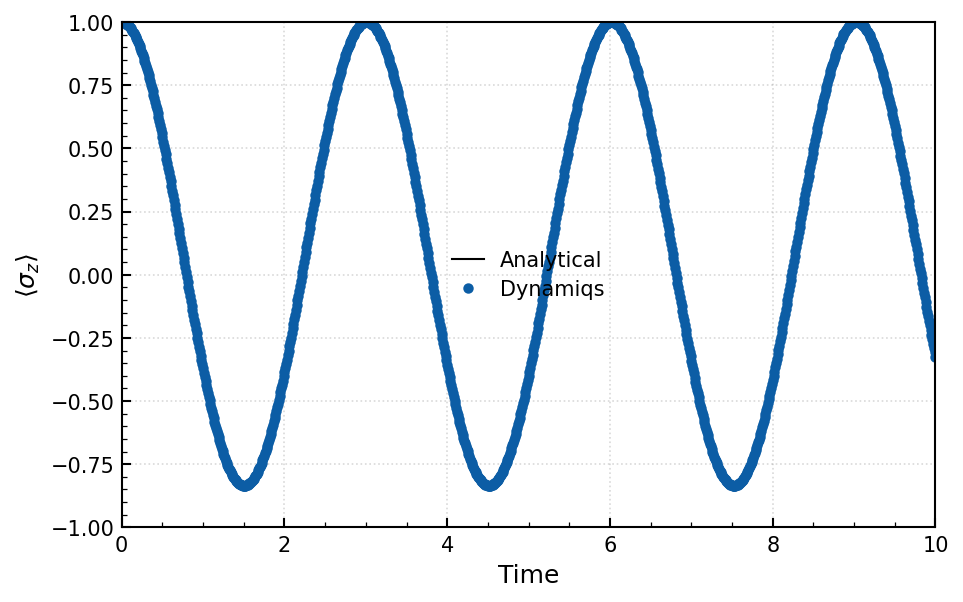

In [6]:
# analytical result
Omega_star = jnp.sqrt(delta**2 + Omega**2)  # generalized Rabi frequency
excited_pop = Omega / Omega_star * jnp.sin(tsave * Omega_star)  # excited population
sigmaz_analytical = 1 - 2 * excited_pop**2  # expectation value of sigma_z

# plot results
plt.plot(tsave, sigmaz_analytical, 'k', lw=1.0)
plt.plot(tsave, result.expects[0].real, 'oC0', ms=4)

# formatting
plt.xlabel('Time')
plt.ylabel(r'$\langle \sigma_z \rangle$')
plt.xlim(0, 10)
plt.ylim(-1, 1)
plt.legend(('Analytical', 'Dynamiqs'))

**`Forward simulation`**

In [7]:
from torch.utils.data import Dataset , DataLoader , Sampler



class RabiDataset(Dataset):
  def __init__(self,T,SigmaZ,device):
    super().__init__()
    self.T = T
    self.SigmaZ = SigmaZ
    self.residuals = torch.ones_like(self.T).to(device)
    self.residuals *=100

  def __len__(self):
    return len(self.T)

  def __getitem__(self, index) :
    return index,self.T[index],self.SigmaZ[index]


## Side note: how the physics is enforced during training

A PINN is trained by checking the Schrödinger equation at a set of chosen times, called **collocation points**. Training on a plain uniform grid of points is the simplest choice, but it can converge slowly or get stuck, especially for oscillating solutions like this one. Much of the effort goes into regions the network has already learned.

A known fix is **residual-based adaptive sampling**: sample more points where the equation is currently violated most, so training focuses on the hard regions. See Lu et al., [*A comprehensive study of non-adaptive and residual-based adaptive sampling for physics-informed neural networks*](https://arxiv.org/abs/2207.10289).

**What we compare.** Two runs, each training a fresh network with the same architecture, epoch budget and 1001-point grid on $t\in[0,10]$:

1. **Uniform:** the points are visited in the same fixed order every epoch.
2. **Residual-adaptive:** each epoch, points with larger current error tend to be visited first (`AdaptiveResidualSampler`).

The only difference between the runs is this ordering.



In [8]:
class AdaptiveResidualSampler(Sampler):
  def __init__(self,dataset):
    super().__init__()
    self.dataset = dataset


  def __iter__(self):
    porbabilities = torch.nn.functional.softmax(self.dataset.residuals)
    indecies = torch.multinomial(porbabilities, num_samples=len(self.dataset), replacement=False)
    return iter(indecies)

  def __len__(self):
    len(self.dataset)

In [9]:
import numpy as np
T = torch.from_numpy(np.array(tsave, copy=True))
SigmaZ = torch.from_numpy(np.array(result.expects[0].real, copy=True))
T_train , T_test = T , T
SigmaZ_train , SigmaZ_test = SigmaZ , SigmaZ

train_data = RabiDataset(T_train , SigmaZ_train,device)
test_data = RabiDataset(T_test , SigmaZ_test,device)

sampler = AdaptiveResidualSampler(train_data)



In [10]:
batch_size = 128
lr = 1e-3
test_loader = DataLoader(test_data , 1001)


## Method: physics-informed neural network (PINN)

A PINN replaces a numerical solver with a neural network trained to satisfy the governing equation itself. No solution data is used, as in the proposal's §3.

**General form.** Suppose the unknown $u(t)$ obeys a differential equation with a prescribed initial (or boundary) condition:

$$\mathcal{N}[u](t) = 0 \quad \text{for } t\in[0,T], \qquad \mathcal{B}[u] = f \text{ at } t=0,$$

where $f$ is the given initial (or boundary) data. A network $u_\theta(t)$ is trained to minimize

$$\mathcal{L}(\theta) = \lambda_\mathrm{phys}\,\frac{1}{N}\sum_{k=1}^{N}\big\|\mathcal{N}[u_\theta](t_k)\big\|^2 \;+\; \lambda_\mathrm{ic}\,\big\|\mathcal{B}[u_\theta]-f\big\|^2 \;+\; \sum_m \lambda_m\,\mathcal{L}_m,$$

where the $t_k$ are the sampled **collocation points**. The terms are:

1. **Physics residual.** Measures how badly the network violates the equation at the collocation points. This is the term that makes the method physics-informed.
2. **Initial/boundary condition.** Penalizes the mismatch with the prescribed data $f$. It pins down which of the many solutions of the equation we want.
3. **Optional extra constraints** $\mathcal{L}_m$. These are problem-specific properties the solution must satisfy but that the other terms don't enforce by themselves.

The $\lambda$ weights balance the terms. The derivatives inside $\mathcal{N}$ are computed by automatic differentiation of the network, so the network must be smooth, which is why `tanh` activations are used.

**Our case: the driven qubit.** The unknown is the qubit state $\psi_\theta(t)$, the two complex amplitudes of $|0\rangle$ and $|1\rangle$. The general pieces become:

- **Equation:** the Schrödinger equation,
$$\mathcal{N}[\psi] = i\,\partial_t\psi - H\psi, \qquad H = \delta\,\sigma_z + \Omega\,\sigma_x.$$
- **Initial condition:** $\mathcal{B}[\psi]=\psi(0)$ with $f=|0\rangle$.
- **Extra constraint:** normalization, $\big(\|\psi\|^2-1\big)^2$. It is not redundant: the Schrödinger equation is linear, so any scalar multiple of a solution also has zero residual, and nothing else fixes the overall scale of the output.

Putting them together, the loss we minimize is

$$\mathcal{L}(\theta) = \lambda_\mathrm{phys}\,\frac{1}{N}\sum_{k=1}^{N}\big\|\,i\,\partial_t\psi_\theta(t_k) - H\psi_\theta(t_k)\big\|^2 \;+\; \lambda_\mathrm{ic}\,\big\|\psi_\theta(0)-|0\rangle\big\|^2 \;+\; \lambda_\mathrm{norm}\,\frac{1}{N}\sum_{k=1}^{N}\big(\|\psi_\theta(t_k)\|^2-1\big)^2.$$

In [11]:
import torch.nn as nn
from torch.func import jacrev,vmap

class Pinn(nn.Module):
  def __init__(self,layers) :
    super().__init__()
    self.model = nn.Sequential()
    for i in range(len(layers)-1):
      self.model.add_module(f"Linear{str(i)}" , nn.Linear(layers[i] , layers[i+1]))
      self.model.add_module(f"activation{str(i)}" , nn.Tanh())
    self.model.add_module(f"output" , nn.Linear(layers[-1] , 4))

  def forward(self,x):
    return self.model(x)

In [12]:
def sigreg_weak_loss(x, sketch_dim=64):
    """
    Forces Covariance(x) ~ Identity.
    Matches the 2nd Moment (Spherical Cloud).
    """
    N, C = x.size()
    # 1. Sketching (Optional for C=512, but good for consistency)
    if C > sketch_dim:
        S = torch.randn(sketch_dim, C, device=x.device) / (C ** 0.5)
        x = x @ S.T  # [N, sketch_dim]
    else:
        sketch_dim = C

    # 2. Centering & Covariance
    x = x - x.mean(dim=0, keepdim=True)
    cov = (x.T @ x) / (N - 1 + 1e-6)

    # 3. Target Identity
    target = torch.eye(sketch_dim, device=x.device)

    # 4. Off-diagonal suppression + Diagonal maintenance
    return torch.norm(cov - target, p='fro')

In [13]:
model = Pinn([1,10,20,]).to(device)

optimizer = torch.optim.Adam(params=model.parameters() , lr = lr)
print(H)


def calc_forward(x):
  return model(x)

calc_jacobian = jacrev(calc_forward)
imaginary_vector = torch.tensor([1.0,1.0,1.0j,1.0j]).unsqueeze(1).to(device)

def calculate_derveative(x):
  derevatives = vmap(calc_jacobian)(x)
  derevatives =  derevatives*imaginary_vector
  d_psi = derevatives[:,[0,1],:] + derevatives[:,[2,3],:]


  return d_psi.squeeze()

def calculate_derveative_aproximation(model,x):
    

    h = torch.tensor([1e-6]).to(device)
    backward = model(x-h)
    forward = model(x+h)

    derevatives = ((forward - backward)/(2*h)).unsqueeze(-1)
    derevatives =  derevatives*imaginary_vector
    d_psi = derevatives[:,[0,1],:] + derevatives[:,[2,3],:]
    
  
    


    return d_psi.squeeze()

def pde_resiual(i,psi,d_psi,H):
  psi = psi.unsqueeze(-1)*imaginary_vector
  psi = psi[:,[0,1]] + psi[:,[2,3]]
  psi = psi.squeeze()

  residual = torch.tensor([1.0j]).unsqueeze(1).to(device) * d_psi - psi @ H.T.to(torch.complex64).to(device)
  residual = torch.linalg.norm(residual , dim = 1)
  train_data.residuals[i] = residual
  residual = residual.mean()
  return residual


def boundary_loss():
  boundary = torch.tensor([0.0]).unsqueeze(1).to(device)
  state = model(boundary).unsqueeze(-1)*imaginary_vector
  state = state[:,[0,1]] + state[:,[2,3]]

  loss = torch.linalg.norm(state , dim = 0 ) **2
  loss = torch.nn.functional.mse_loss(loss[0] , torch.tensor([1.0]).to(device)) + torch.nn.functional.mse_loss(loss[1] , torch.tensor([0.0]).to(device))
  return loss

def norm_loss(psi):
  psi = psi.unsqueeze(-1)
  psi = psi * imaginary_vector
  psi = psi[:,[0,1],:] + psi[:,[2,3],:]
  psi = torch.linalg.norm(psi,dim = -1)**2
  sum = torch.sum(psi ,dim = -1)
  loss = torch.nn.functional.mse_loss(sum , torch.ones_like(sum))
  return loss


tensor([[ 0.3000+0.j,  1.0000+0.j],
        [ 1.0000+0.j, -0.3000+0.j]], device='cuda:0')


In [14]:
forward_uniform_sampling_error = []
forward_enahnced_sampling_error = []
_sampling = {"uniform" : [],"enhanced":[]}
train_loader = DataLoader(train_data,batch_size,sampler = sampler)
loaders = {"uniform":DataLoader(train_data,batch_size),"enhanced":DataLoader(train_data,batch_size,sampler = sampler)}
colors = {"uniform" :"c" , "enhanced" : "b"}

In [15]:
epochs = 10000

Parameters: 434
epoch: 0


/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:330.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


epoch: 1000
epoch: 2000
epoch: 3000
epoch: 4000
epoch: 5000
epoch: 6000
epoch: 7000
epoch: 8000
epoch: 9000


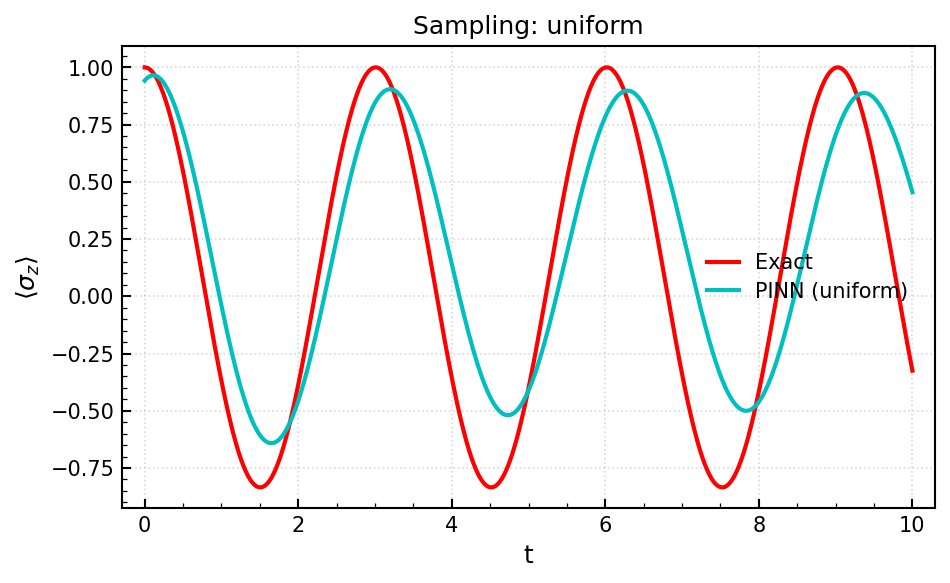

Parameters: 434
epoch: 0


/tmp/ipykernel_136/2814703387.py:8: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  porbabilities = torch.nn.functional.softmax(self.dataset.residuals)


epoch: 1000
epoch: 2000
epoch: 3000
epoch: 4000
epoch: 5000
epoch: 6000
epoch: 7000
epoch: 8000
epoch: 9000


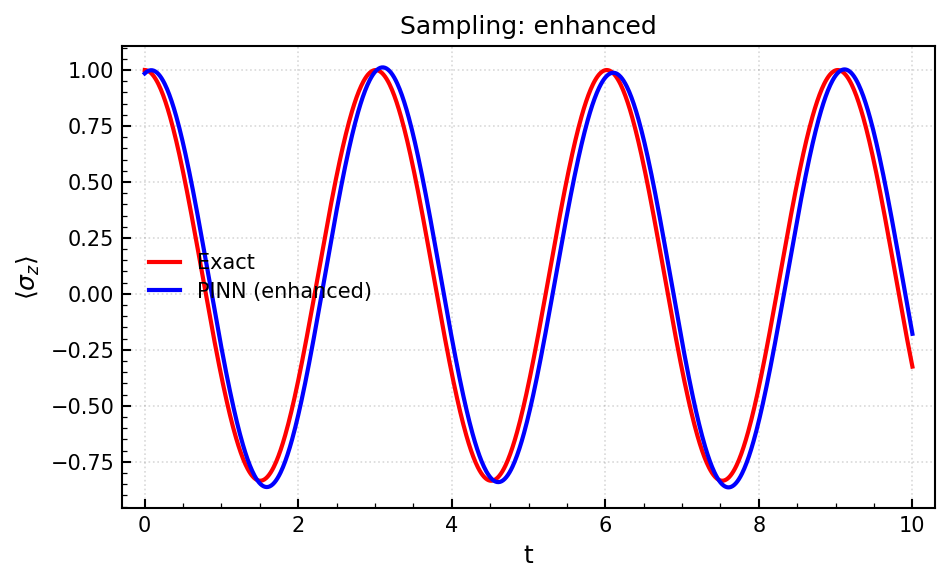

In [16]:



def train_step(i, model, optim, batch, sampling_technique):
    model.train()
    optim.zero_grad()

    psi = model(batch).requires_grad_(True)
    d_psi = calculate_derveative(batch)

    loss = (
        0.6 * norm_loss(psi)
        + boundary_loss()
        + pde_resiual(i, psi, d_psi, H)
    )

    _sampling[sampling_technique].append(loss.item())

    loss.backward()
    optim.step()


def test_step(i, model, batch):
    model.eval()

    batch = batch.to(device)

    psi = model(batch)
    d_psi = calculate_derveative(batch)

    loss = (
        0.1 * norm_loss(psi)
        + 0.3 * boundary_loss()
        + 0.3 * pde_resiual(i, psi, d_psi, H)
    )

    # Convert network output to complex wavefunction
    psi = psi.unsqueeze(-1)
    psi = psi * imaginary_vector

    psi = (
        psi[:, [0, 1], :]
        + psi[:, [2, 3], :]
    )

    # Probabilities
    psi = torch.linalg.norm(psi, dim=-1) ** 2

    
    return psi[:, 0] - psi[:, 1]


for smpl in _sampling.keys():
    model = Pinn([1, 15, 20]).to(device)

    num_params = sum(p.numel() for p in model.parameters())
    print(f"Parameters: {num_params:,}")
    
    optimizer = torch.optim.Adam(
        params=model.parameters(),
        lr=lr
    )
    train_loader = loaders[smpl]
    for j in range(epochs):

        if j % 1000 == 0:
            print(f"epoch: {j}")

        for i, t, y in train_loader:
            batch = t.unsqueeze(1).to(device).requires_grad_(True)

            train_step(
                i,
                model,
                optimizer,
                batch,
                smpl
            )

    ts, ys, preds = [], [], []
    for i, t, y in test_loader:
        sigma_z = test_step(i, model, t.unsqueeze(1))
        ts.append(t.detach().cpu())
        ys.append(y.detach().cpu())
        preds.append(sigma_z.detach().cpu())

    t_all = torch.cat(ts)
    y_all = torch.cat(ys)
    p_all = torch.cat(preds)

    # One figure per sampling technique
    plt.figure(figsize=(7, 4))
    plt.plot(t_all, y_all, "r", label="Exact")
    plt.plot(t_all, p_all, colors[smpl], label=f"PINN ({smpl})")
    plt.xlabel("t")
    plt.ylabel(r"$\langle \sigma_z \rangle$")
    plt.title(f"Sampling: {smpl}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

/tmp/ipykernel_136/1554962702.py:6: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /pytorch/aten/src/ATen/native/Convolution.cpp:1025.)
  y_smooth = torch.conv1d(


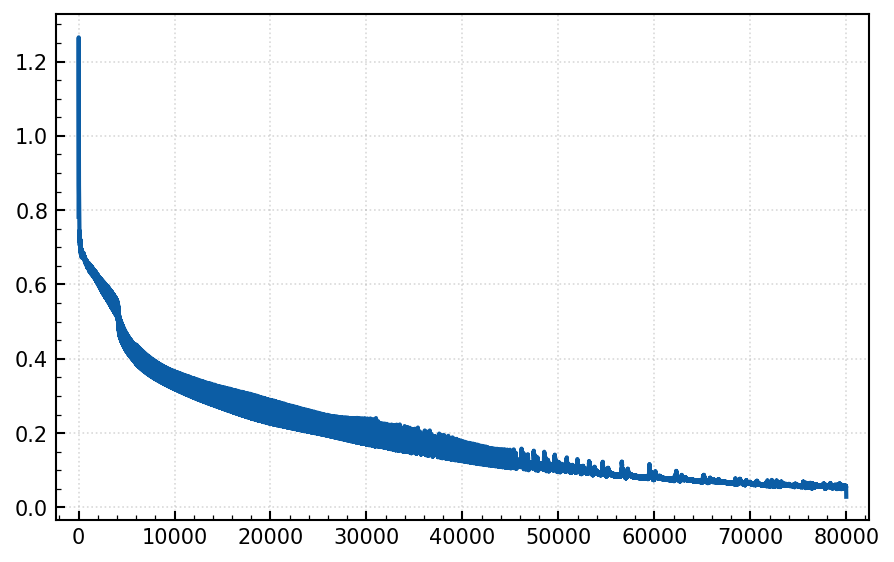

In [17]:
                 
y = torch.tensor(_sampling["uniform"], dtype=torch.float32).flatten()

window = 30
kernel = torch.ones(window) / window

y_smooth = torch.conv1d(
    y[None, None, :],
    kernel[None, None, :],
    padding="same"
).squeeze()

t = torch.arange(len(y))

plt.plot(t, y_smooth)
plt.show()    

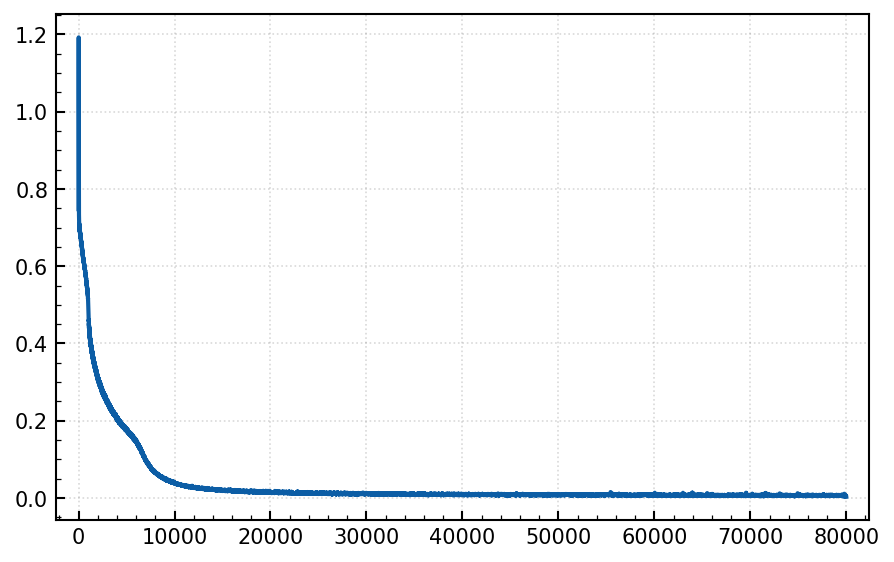

In [18]:
                 
y = torch.tensor(_sampling["enhanced"], dtype=torch.float32).flatten()

window = 30
kernel = torch.ones(window) / window

y_smooth = torch.conv1d(
    y[None, None, :],
    kernel[None, None, :],
    padding="same"
).squeeze()

t = torch.arange(len(y))

plt.plot(t, y_smooth)
plt.show()    

In [19]:
forward_uniform_sampling_error = []
forward_enahnced_sampling_error = []
_sampling = {"uniform" : [],"enhanced":[]}
train_loader = DataLoader(train_data,batch_size,sampler = sampler)
loaders = {"uniform":DataLoader(train_data,batch_size),"enhanced":DataLoader(train_data,batch_size,sampler = sampler)}
colors = {"uniform" :"c" , "enhanced" : "b"}

**Inverse for the hamiltonian's parameters
**

## Inverse problem: identifying the Hamiltonian from a measured trace

**Setting.** Suppose we cannot look inside the device. All we have is a measured trace $\langle\sigma_z\rangle(t)$ on $t\in[0,10]$, and the *form* of the Hamiltonian (two-level, constant drive), but not its parameters $(\delta,\Omega)$. Can the network recover them? This is the minimal case of the hardware identification in §8.2.

**General form.** In the forward problem the equation is fully known and we solve for $u$. In the inverse problem the equation contains unknown parameters $\mu$, and we are given measurements $y$ of the solution:

$$\mathcal{N}[u;\mu](t) = 0, \qquad \mathcal{M}[u] = y,$$

where $\mathcal{M}$ is the measurement map, the part of $u$ we can observe. The network $u_\theta$ and the parameters $\mu$ are trained together by minimizing

$$\mathcal{L}(\theta,\mu) = \lambda_\mathrm{data}\,\big\|\mathcal{M}[u_\theta]-y\big\|^2 \;+\; \lambda_\mathrm{phys}\,\frac{1}{N}\sum_{k=1}^{N}\big\|\mathcal{N}[u_\theta;\mu](t_k)\big\|^2 \;+\; \lambda_\mathrm{extra}\,\mathcal{L}_\mathrm{extra}.$$

1. **Data term.** Ties the network's predicted measurement to the measured one.
2. **Physics residual.** Evaluated with the *proposed* parameters $\mu$, so the parameters that make the network consistent with both the data and the physics are the ones selected.
3. **Extra constraints** $\mathcal{L}_\mathrm{extra}$. Problem-specific properties the solution must satisfy, as in the forward problem.

**Our case.** The unknown parameters are $\mu=(\delta,\Omega)$ inside $H_\mu=\delta\,\sigma_z+\Omega\,\sigma_x$, and the only measurement is $\mathcal{M}[\psi]=\langle\psi|\sigma_z|\psi\rangle$:

$$\mathcal{L} = \lambda_\mathrm{data}\big|\langle\psi_\theta|\sigma_z|\psi_\theta\rangle - y\big|^2 \;+\; \lambda_\mathrm{phys}\,\frac{1}{N}\sum_{k=1}^{N}\big\|\,i\,\partial_t\psi_\theta(t_k) - H_\mu\psi_\theta(t_k)\big\|^2 \;+\; \lambda_\mathrm{norm}\,\frac{1}{N}\sum_{k=1}^{N}\big(\|\psi_\theta(t_k)\|^2-1\big)^2.$$

The state network $\psi_\theta$ is trained together with a second small network that maps time to the parameters $(\delta,\Omega)$. Here the true parameters are constant, but this design also extends to time-varying pulses, which is the goal of the proposal.

**What the data can and cannot identify.** The measured trace depends on $\delta$ and $\Omega$ only through their squares. So $\langle\sigma_z\rangle(t)$ alone can identify their sizes, $|\delta|$ and $|\Omega|$, but not their signs. Recovering signs would need additional observables. This is a limit of the data, not of the method.



Parameters: 434
epoch: 0


/tmp/ipykernel_136/847486328.py:82: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  sigmaz = torch.from_numpy(np.array(dq.sigmaz(), copy=True)).to(device)


epoch: 1000
epoch: 2000
epoch: 3000
epoch: 4000
epoch: 5000
epoch: 6000
epoch: 7000
epoch: 8000
epoch: 9000


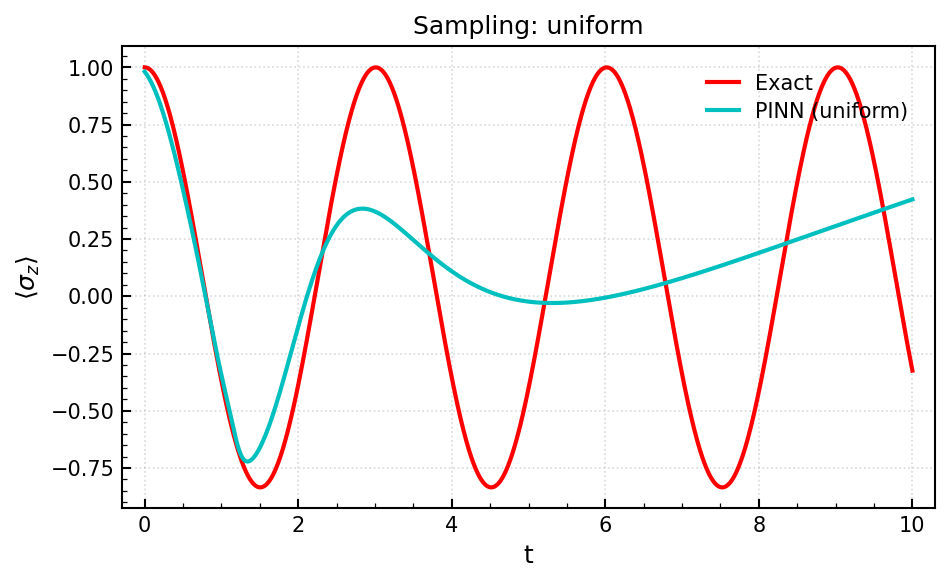

epoch: 0


/tmp/ipykernel_136/2814703387.py:8: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  porbabilities = torch.nn.functional.softmax(self.dataset.residuals)


epoch: 1000
epoch: 2000
epoch: 3000
epoch: 4000
epoch: 5000
epoch: 6000
epoch: 7000
epoch: 8000
epoch: 9000


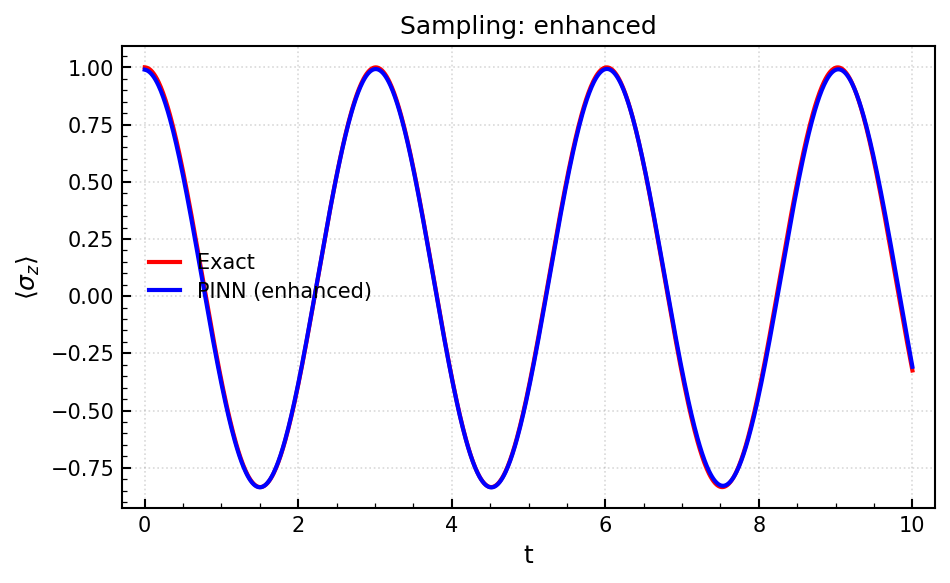

In [20]:

num_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {num_params:,}")
class Paramerizer(nn.Module):
  def __init__(self):
    super().__init__()
    self._model = nn.Sequential(nn.Linear(1,8) , nn.Tanh() , nn.Linear(8,14), nn.Tanh() , nn.Linear(14,2))

  def forward(self,x):
    return self._model(x)


def boundary_loss(boundary , y):
  boundary = boundary.to(device)
  state = model(boundary).unsqueeze(-1)*imaginary_vector
  state = state[:,[0,1]] + state[:,[2,3]]
  loss = state.real ** 2 + state.imag ** 2
  loss = loss.squeeze()  
  loss = torch.nn.functional.mse_loss(loss[...,0] -loss[...,1] , y.to(device))
  return loss

def train_step(i, model, optim, batch,y, sampling_technique):
    model.train()
    optim.zero_grad()

    psi = model(batch).requires_grad_(True)
    params = parametrizer(batch)
  
    H = params[...,0][:,None,None] * sigmaz + params[...,1][:,None,None] * sigmax
    H = H.mean(dim = 0)
    d_psi = calculate_derveative(batch)

    loss = (
        0.6 * norm_loss(psi)
        + boundary_loss(batch,y)
        + pde_resiual(i, psi, d_psi, H)
    )

    _sampling[sampling_technique].append(loss.item())

    loss.backward()
    optim.step()
    



def test_step(i, model,y, batch):
    model.eval()

    batch = batch.to(device)

    psi = model(batch)
    d_psi = calculate_derveative(batch)

    loss = (
        0.1 * norm_loss(psi)
        + 0.3 * boundary_loss(batch,y)
        + 0.3 * pde_resiual(i, psi, d_psi, H)
    )

    # Convert network output to complex wavefunction
    psi = psi.unsqueeze(-1)
    psi = psi * imaginary_vector

    psi = (
        psi[:, [0, 1], :]
        + psi[:, [2, 3], :]
    )

    # Probabilities
    psi = torch.linalg.norm(psi, dim=-1) ** 2

    

    return psi[:, 0] - psi[:, 1]


for smpl in _sampling.keys():
    model = Pinn([1, 15, 20]).to(device)

    parametrizer = Paramerizer().to(device)

    sigmaz = torch.from_numpy(np.array(dq.sigmaz(), copy=True)).to(device)
    sigmax = torch.from_numpy(np.array(dq.sigmax(), copy=True)).to(device)
    optimizer = torch.optim.Adam(params=list(model.parameters())+list(parametrizer.parameters()) , lr = lr)
    train_loader = loaders[smpl]
    for j in range(epochs):

        if j % 1000 == 0:
            print(f"epoch: {j}")

        for i, t, y in train_loader:
            batch = t.unsqueeze(1).to(device).requires_grad_(True)

            train_step(
                i,
                model,
                optimizer,
                batch,
                y,
                smpl
            )

    ts, ys, preds = [], [], []
    for i, t, y in test_loader:
        sigma_z = test_step(i, model, y, t.unsqueeze(1))
        ts.append(t.detach().cpu())
        ys.append(y.detach().cpu())
        preds.append(sigma_z.detach().cpu())

    t_all = torch.cat(ts)
    y_all = torch.cat(ys)
    p_all = torch.cat(preds)

    # One figure per sampling technique
    plt.figure(figsize=(7, 4))
    plt.plot(t_all, y_all, "r", label="Exact")
    plt.plot(t_all, p_all, colors[smpl], label=f"PINN ({smpl})")
    plt.xlabel("t")
    plt.ylabel(r"$\langle \sigma_z \rangle$")
    plt.title(f"Sampling: {smpl}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

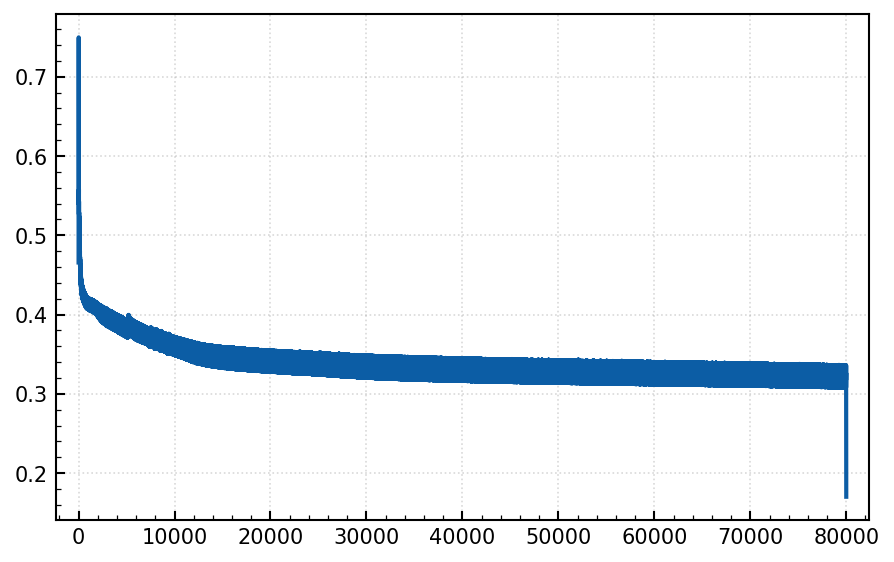

In [21]:
                 
y = torch.tensor(_sampling["uniform"], dtype=torch.float32).flatten()

window = 30
kernel = torch.ones(window) / window

y_smooth = torch.conv1d(
    y[None, None, :],
    kernel[None, None, :],
    padding="same"
).squeeze()

t = torch.arange(len(y))

plt.plot(t, y_smooth)
plt.show()    

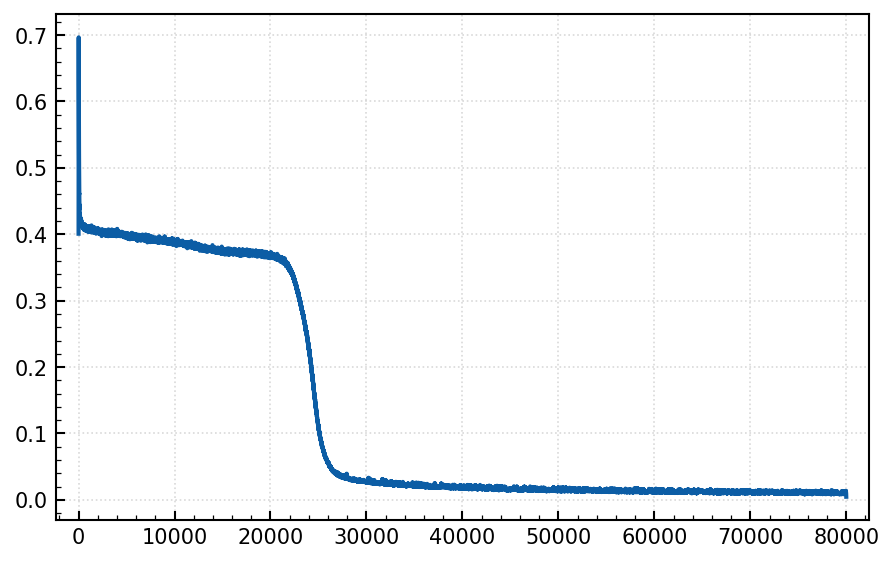

In [22]:
                 
y = torch.tensor(_sampling["enhanced"], dtype=torch.float32).flatten()

window = 30
kernel = torch.ones(window) / window

y_smooth = torch.conv1d(
    y[None, None, :],
    kernel[None, None, :],
    padding="same"
).squeeze()

t = torch.arange(len(y))

plt.plot(t, y_smooth)
plt.show()    

In [23]:
predicted_params = parametrizer(torch.rand([1000,1]).to(device)).mean(0)

real_params = torch.tensor([delta,Omega])

print(f"real delta : {real_params[0]} , predicted delta {predicted_params[0]}")
print(f"real Omega : {real_params[1]} , predicted Omega {predicted_params[1]}")

print(f"absolute delta error: {real_params[0]-predicted_params[0]} ,absolute Omega error {real_params[1]-predicted_params[1]}")

real delta : 0.30000001192092896 , predicted delta -0.3535864055156708
real Omega : 1.0 , predicted Omega -0.9794908761978149
absolute delta error: 0.6535863876342773 ,absolute Omega error 1.979490876197815
